# **Sobre o conjunto de dados** <p>
"Unicórnio" é um termo usado na indústria de capital de risco para descrever uma startup de capital fechado com valor superior a US$ 1 bilhão. O termo foi popularizado pela primeira vez pela capitalista de risco Aileen Lee, fundadora da Cowboy Ventures, um fundo de capital de risco com sede em Palo Alto, Califórnia.

Unicórnios também podem se referir a um fenômeno de recrutamento no setor de recursos humanos (RH). Os gerentes de RH podem ter grandes expectativas para preencher um cargo, levando-os a procurar candidatos com qualificações superiores às exigidas para um cargo específico. Em essência, esses gerentes estão procurando um unicórnio, o que leva a uma desconexão entre seu candidato ideal e quem eles podem contratar do grupo de pessoas disponíveis.

[Download da base de dados](https://www.kaggle.com/ramjasmaurya/unicorn-startups)


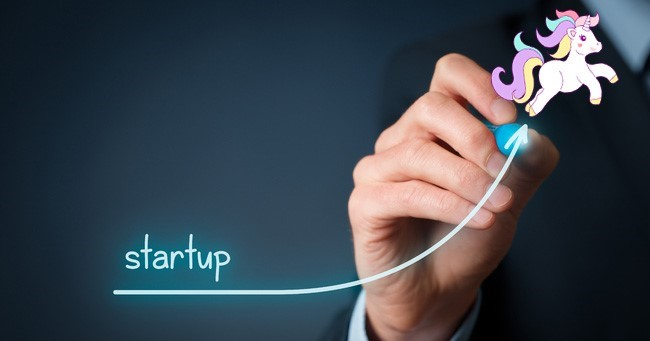

In [1]:
#Importando Bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')



In [28]:
#Lendo os dados
Base_Dados = pd.read_csv('/content/unicorns till sep 2022.csv')
Base_Dados.head()

,Company,Valuation ($B),Date Joined,Country,City,Industry,Investors
0,ByteDance,$140,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S..."
1,SpaceX,$127,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen..."
2,SHEIN,$100,7/3/2018,China,Shenzhen,E-commerce & direct-to-consumer,"Tiger Global Management, Sequoia Capital China..."
3,Stripe,$95,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG"
4,Canva,$40,1/8/2018,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat..."


In [29]:
Base_Dados.shape


(1186, 7)

In [31]:
# Renomeando colunas
Base_Dados.rename( columns={
    'Unnamed: 0' : 'Id',
    'Company' : 'Empresa',
    'Valuation ($B)' : 'Valor ($)',
    'Date Joined' : 'Data de Adesão',
    'Country' : 'Pais',
    'City' : 'Cidade',
    'Industry': 'Setor',
    'Select Investors': 'Investidores',
}, inplace=True )

In [33]:
Base_Dados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1186 entries, 0 to 1185
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Empresa         1186 non-null   object
 1   Valor ($)       1186 non-null   object
 2   Data de Adesão  1186 non-null   object
 3   Pais            1186 non-null   object
 4   City            1186 non-null   object
 5   Setor           1186 non-null   object
 6   Investors       1168 non-null   object
dtypes: object(7)
memory usage: 65.0+ KB


In [34]:
#Valores nulos
Base_Dados.isnull().sum()

,0
Empresa,0
Valor ($),0
Data de Adesão,0
Pais,0
City,0
Setor,0
Investors,18


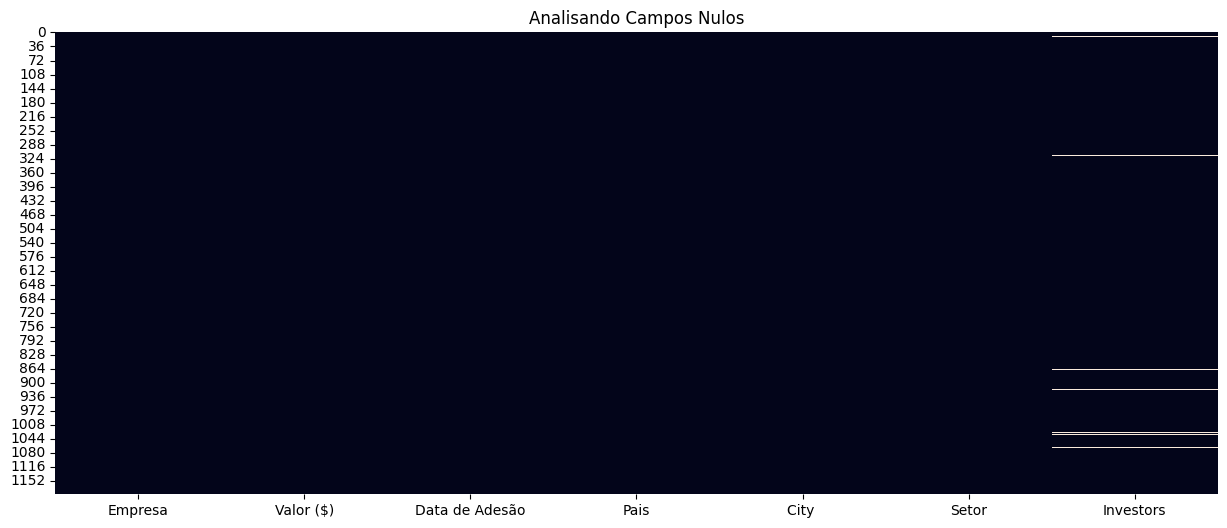

In [35]:
# Campos nulos em Gráfico
plt.figure( figsize=(15,6) )
plt.title('Analisando Campos Nulos')
sns.heatmap( Base_Dados.isnull(), cbar=False );

In [41]:
# Valores Unicos - Rank
Base_Dados['Setor'].value_counts()

,count
Setor,
Fintech,239
Internet software & services,224
E-commerce & direct-to-consumer,103
Health,94
Artificial intelligence,74
Other,65
"Supply chain, logistics, & delivery",65
Cybersecurity,58
Data management & analytics,45


In [43]:
Analise =  Base_Dados['Pais'].value_counts( normalize=False )

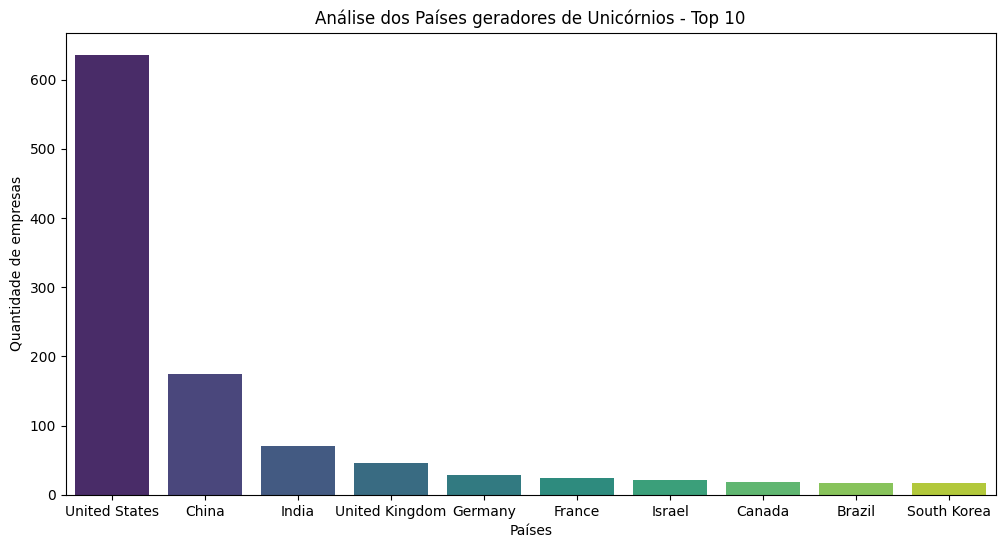

In [44]:
#Gráfico dos Países mais Geradores de Unicórnios
plt.figure( figsize=(12, 6) )
plt.title('Análise dos Países geradores de Unicórnios - Top 10')

sns.barplot(
    x=Analise.index[0:10],
    y=Analise.head(10),
    palette='viridis'
)

plt.xlabel('Países')
plt.ylabel('Quantidade de empresas')

plt.show()

In [45]:
# Transformando a coluna Valor
Base_Dados['Valor ($)'] = pd.to_numeric( Base_Dados['Valor ($)'].apply( lambda Linha: Linha.replace('$', '') ) )

Base_Dados.head()

,Empresa,Valor ($),Data de Adesão,Pais,City,Setor,Investors
0,ByteDance,140.0,4/7/2017,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S..."
1,SpaceX,127.0,12/1/2012,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen..."
2,SHEIN,100.0,7/3/2018,China,Shenzhen,E-commerce & direct-to-consumer,"Tiger Global Management, Sequoia Capital China..."
3,Stripe,95.0,1/23/2014,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG"
4,Canva,40.0,1/8/2018,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat..."


In [46]:
#Setor com maior valor acumulado

Base_Dados.groupby('Setor')['Valor ($)'].sum().sort_values( ascending=False )

,Valor ($)
Setor,
Fintech,855.43
Internet software & services,660.93
E-commerce & direct-to-consumer,387.19
Artificial intelligence,315.01
Other,293.72
Health,233.16
"Supply chain, logistics, & delivery",211.47
Cybersecurity,147.00
Data management & analytics,141.79


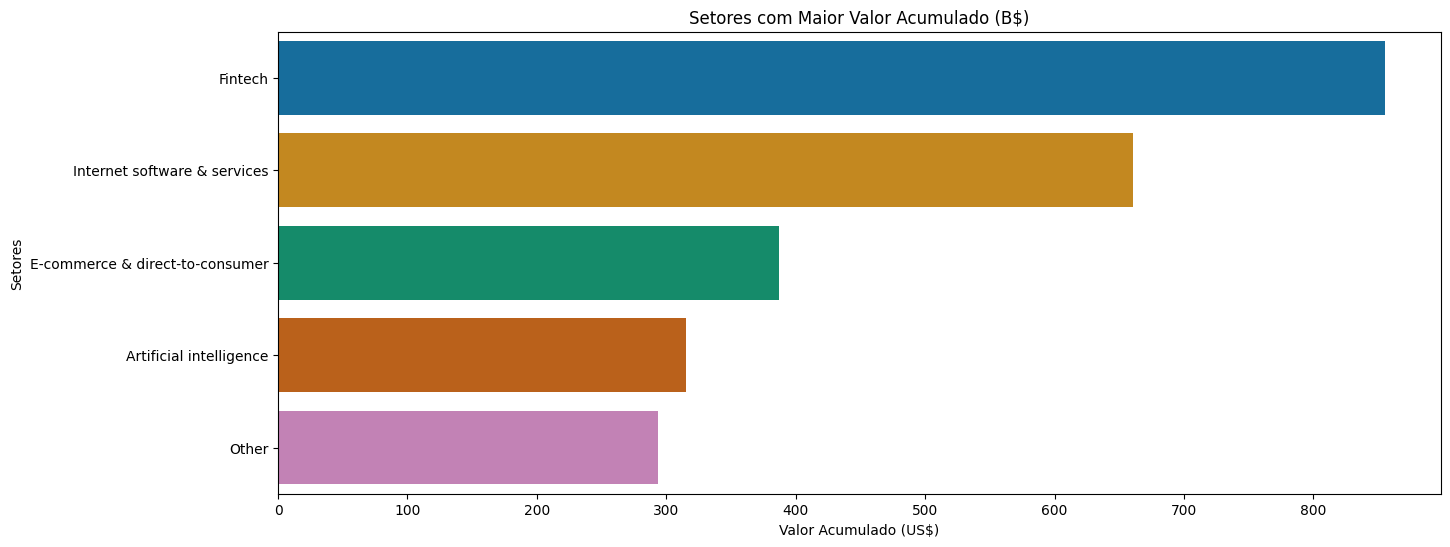

In [47]:
plt.figure(figsize=(15, 6))
plt.title('Setores com Maior Valor Acumulado (B$)')

Analise_setor = Base_Dados.groupby('Setor')['Valor ($)'].sum().sort_values(ascending=False)

sns.barplot(
    x=Analise_setor.values[0:5],
    y=Analise_setor.index[0:5],
    palette='colorblind'
)

plt.xlabel('Valor Acumulado (US$)')
plt.ylabel('Setores')

plt.show()

In [48]:
# Conversão para Data
Base_Dados['Data de Adesão'] = pd.to_datetime( Base_Dados['Data de Adesão'] )

Base_Dados['Data de Adesão'].head()

,Data de Adesão
0,2017-04-07
1,2012-12-01
2,2018-07-03
3,2014-01-23
4,2018-01-08


In [58]:
# Extrair o Ano
Base_Dados['Ano'] = pd.DatetimeIndex( Base_Dados['Data de Adesão'] ).year
Base_Dados.head()

,Empresa,Valor ($),Data de Adesão,Pais,City,Setor,Investors,Mes,Ano
0,ByteDance,140.0,2017-04-07,China,Beijing,Artificial intelligence,"Sequoia Capital China, SIG Asia Investments, S...",4,2017
1,SpaceX,127.0,2012-12-01,United States,Hawthorne,Other,"Founders Fund, Draper Fisher Jurvetson, Rothen...",12,2012
2,SHEIN,100.0,2018-07-03,China,Shenzhen,E-commerce & direct-to-consumer,"Tiger Global Management, Sequoia Capital China...",7,2018
3,Stripe,95.0,2014-01-23,United States,San Francisco,Fintech,"Khosla Ventures, LowercaseCapital, capitalG",1,2014
4,Canva,40.0,2018-01-08,Australia,Surry Hills,Internet software & services,"Sequoia Capital China, Blackbird Ventures, Mat...",1,2018


In [56]:
# Empresas que se tornaram unicórnios em cada ano até 2022
Analise_ano = Base_Dados['Ano'].value_counts( normalize=False )
Analise_ano

,count
Ano,
2021,529
2022,228
2020,108
2019,102
2018,98
2017,44
2015,34
2016,21
2014,12


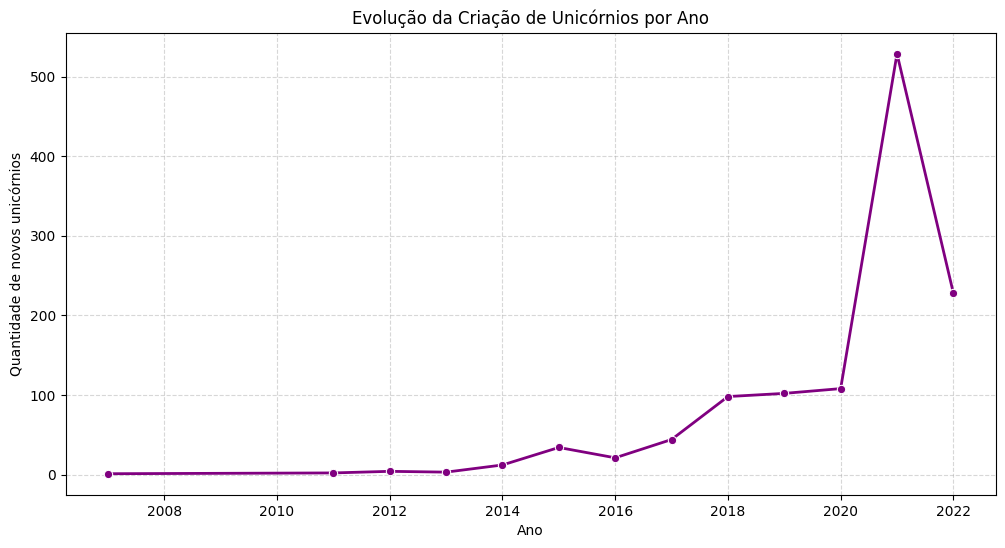

In [57]:
#Empresa que se tornaram unicórnios ao decorrer dos anos
analise_ordenada = Analise_ano.sort_index(ascending=False)

plt.figure(figsize=(12, 6))
plt.title('Evolução da Criação de Unicórnios por Ano')

sns.lineplot(x=analise_ordenada.index, y=analise_ordenada.values, marker='o', color='purple', linewidth=2)

plt.xlabel('Ano')
plt.ylabel('Quantidade de novos unicórnios')
plt.grid(True, linestyle='--', alpha=0.5)

plt.show()